# EEI-303 – Processamento de Voz e Áudio

## 24202631372 - Matheus Costa Damasceno

---

# Aula 10 - Laboratório 3 - Noções de Psicoacústica e testes psicoacústicos

O material desta aula foi adaptado de:

1. Dutoit, T. and Moreau, N. How is sound processed in an MP3 player?, In: Applied Signal Processing, Edited by Duotit, T. and Narques, F., Chapter 3, Springer, 2009

2. HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.

3. ~~https://edisciplinas.usp.br/pluginfile.php/7579962/mod_resource/content/0/Aula8%20-%20MedidasDaOndaSonora.pdf~~

As atividades deverão ser realizadas no ambiente COLAB ou em Jupyter Notebook e o arquivo, contendo os resultados e as respostas das questões, enviado em formato .ipynb pelo formulário.

In [25]:
# !pip install IPython==7.32.0

In [26]:
#@title
import scipy.signal as signal
import numpy as np
import scipy
import matplotlib.pyplot as plt
import librosa
from pylab import *
from IPython.display import Audio
from librosa.display import specshow

In [27]:
#@title
# Downsampling
def decimate(x, q):
    # Downsample the signal
    sl = [slice(None)] * x.ndim
    sl = slice(None, None, q)

    return x[sl]

# Upsampling
def upsample(x, p):
    # upsample the signal
    ylen = p*len(x)
    y    = np.zeros(ylen)
    sl = [slice(None)] * y.ndim
    sl = slice(None, None, p)
    y[sl] = x
    return y

# Quantization
def quantize(x, S):
    X = x.reshape((-1,1))
    S = S.reshape((1,-1))
    dists = abs(X-S)

    nearestIndex = dists.argmin(axis=1)
    quantized = S.flat[nearestIndex]

    return quantized.reshape(x.shape)

#Plot frequency and phase response - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz(b,a=1):
    w,h = signal.freqz(b,a)
    h_dB = 20 * np.log10 (abs(h))
    plt.figure(figsize=(12,6))
    subplot(211)
    plot(w/max(w),h_dB)
    ylabel('Amplitude')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Frequency response')
    plt.grid(True)
    subplot(212)
    h_Phase = unwrap(arctan2(imag(h),real(h)))
    plot(w/max(w),h_Phase)
    ylabel('Phase (radians)')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Phase response')
    subplots_adjust(hspace=0.5)
    plt.grid(True)

#Plot inpulse response, frequency, phase response and delay group - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz2(b,a=1):
    w,h = signal.freqz(b,a)
    end = len(h)
    h_dB = 20 * np.log10 (abs(h))
    plt.figure(figsize=(12,12))
    subplot(311)
    stem(b)
    ylabel('Amplitude')
    xlabel(r'Samples')
    title(r'Impulse response')
    plt.grid(True)
    subplot(312)
    plot(w/max(w),h_dB)
    ylabel('Amplitude [dB]')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Frequency response')
    plt.grid(True)
    subplot(313)
    h_Phase = unwrap(arctan2(imag(h),real(h)))
    plot(w/max(w),h_Phase)
    ylabel('Phase (radians)')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Phase response')
    subplots_adjust(hspace=0.5)
    plt.grid(True)

#Plot inpulse response, frequency, phase response and delay group - adaptado de http://mpastell.com/pweave/_downloads/FIR_design_rst.html
def mfreqz3(b,a=1):
    w,h = signal.freqz(b,a)
    end = len(h)
    h_dB = 20 * log10 (abs(h))
    plt.figure(figsize=(12,12))
    subplot(411)
    stem(b)
    ylabel('Amplitude')
    xlabel(r'Samples')
    title(r'Impulse response')
    plt.grid(True)
    subplot(412)
    plot(w/max(w),h_dB)
    ylabel('Amplitude')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Frequency response')
    plt.grid(True)
    subplot(413)
    h_Phase = unwrap(arctan2(imag(h),real(h)))
    plot(w/max(w),h_Phase)
    ylabel('Phase (radians)')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Phase response')
    subplots_adjust(hspace=0.5)
    plt.grid(True)
    wd, gd = signal.group_delay((b, a))
    subplot(414)
    plot(wd/max(w),gd)
    ylabel('Samples')
    xlabel(r'Normalized Frequency (x$\pi$rad/sample)')
    title(r'Delay group')
    subplots_adjust(hspace=0.5)
    plt.grid(True)

# O sistema auditivo humano

O sistema auditivo humano, ilustrado na figura abaixo, pode ser divido em três partes:

* A orelha externa: a orelha externa é composta do pavilhão auditivo e do canal auditivo;
* A orelha média: a orelha média é composta pelo tímpano, pelo tubo de Eustáquio, pelas janelas oval, e redonda, e três ossos bem pequenos: o martelo, a bigorna e o estribo;
* A orelha interna: a orelha interna é composta da cóclea, da membrana basilar e dos nervos auditivos.  


Na orelha externa, o pavilhão auditivo realiza a captação dos sons e o direciona para o canal auditivo. Na orelha média, esse sinal é transformado pelo tímpano em movimentos mecânicos que são amplificados pelos três ossículos. Finalmente, é no ouvido interno que esses movimentos mecânicos são transformados em estímulos elétricos para então serem transportados pelos nervos auditivos até o cérebro humano.

<center>

  <img src="https://drive.google.com/uc?id=1n1dJm7PXINIUb7UM7K2xpAeZ5iy-3_hy"
	width="65%" />
</center>

Figura adaptada de: MCLOUGHLIN, I., Applied Speech and Audio Processing, Cambridge University Press, 2009.

# Psicoacústica


A psicoacústica busca compreender a forma de que o ouvido humano é capaz de perceber diferentes sons. Por exemplo, o ouvido humano tende a perceber a amplitude dos sons de forma logarítmica, ao invés de linear. Neste caso, um sinal quantizado logaritmicamente com 8 bits (compansão lei-A ou lei-$\mu$) soa melhor do que um sinal quantizado linearmente com os mesmos 8 bits. A quantização logaritmica com 8 bits é capaz de reproduzir uma resolução de 14 bits, quando comprada com a quantização linear.

Na psicoacústica, diferentes fenômenos são estudados e formam a base de diversos codificadores de áudio implementados até hoje. Dentre eles, podemos destacar três fenômenos:

* Sensibilidade auditiva;
* Mascaramento em frequência;
* Mascaramento temporal;




## Sensibilidade auditiva

A sensibilidade auditiva busca relacionar a intensidade do som perceptível com as diferentes escalas de frequência, baseado no fato de que a resposta em frequência do ouvido humano não é plana. Ou seja, além de ser sensível apenas à uma determinada faixa de frequências (geralmente compreendida entre 20 Hz e 20 kHz), um sinal de 1 kHz com uma determinada intensidade sonora soa mais alto que um sinal de 15 kHz com a mesma intensidade sonora.

Em geral, este limiar é definido com base no nível de pressão sonora, SPL, do inglês Sound Pressure Level, definido por:
\begin{equation}
SPL = 20\text{log}_{10}\frac{P}{P_0} \text{(dB)}
\end{equation}
onde $P_0 = 20\times10^{-6}$ pascal

A figura abaixo apresenta a curva de limiar auditivo humano (&copy; IEEE 2000). Nesta figura, apenas os sinais que se encontram acima desse limiar são considerados audíveis, enquanto que os sinais que se encontram debaixo desse limiar são imperceptíveis ao ouvido humano.

<center>

  <img src="https://drive.google.com/uc?id=1MXGktJ03M2izFtmM8DXCfAatT508V-55"
	width="65%" />
</center>

Figura extraída de: HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.



## Exercício 1

Vamos tocar dois tons puros, um na frequência de 1kHz e outra na frequência de 15kHz. Qual destes tons soou mais alto para você?

Resposta:

Perceptualmente o tom de 1 kHz soa mais alto. Apesar de ambos possuírem a mesma amplitude e duração, a curva de limiar auditivo indica que nossa percepção sonora é mais sensível em 1 kHz do que em 15 kHz. Interessante destacar que ouvindo o som reproduzido no laboratório (com as caixas de som), no fone de ouvido (Arcano Arc-SPH300) e no alto-falante do laptop (Acer Nitro 5), foi possível observar esse padrão nos três, porém a diferença foi menos acentuada no fone de ouvido. Isso possivelmente se deve ao fato do fone de ouvido possuir uma resposta mais plana em relação aos alto-falantes, de modo que estes, por não serem de alta fidelidade, tendem a naturalmente reproduzir as altas frequências com uma intensidade inferior ao fone de ouvido. As análises seguintes considerarão exclusivamente a percepção com o fone.

In [28]:
#@title
T  = 1
f1 = 1000   # frequência do sinal
f2 = 15000   # frequência do sinal
fs = 48000  # taxa de amostragem do sinal
t  = np.linspace(0,T,int(T*fs), endpoint=False)
x1  = np.cos(2*np.pi*f1*t)
x2  = np.cos(2*np.pi*f2*t)

In [29]:
Audio(data=x1, rate=fs) # tom de 1000 Hz

In [30]:
Audio(data=x2, rate=fs) # tom de 15000 Hz

Deste modo, ao invés de quantizar cada faixa de frequências com um número fixo de bits, é possível compactar o dado atribuindo, para cada faixa de frequências, um número diferente de bits, como ilustrado pela figura abaixo. Por exemplo, um trecho de sinal de áudio com faixa de frequências entre 5 kHz a 15 kHz pode ser quantizado com um número menor de bits do que um trecho de sinal de áudio com faixa de frequências entre 100 a 5 kHz, sem que haja uma perda significativa na qualidade do áudio.

<center>

  <img src="https://drive.google.com/uc?id=1iR5toFOBTp9gGK1a0c1tqL8DvZL5bVXo"
	width="65%" />
</center>

Figura extraída de: HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.

### A escala de Bark

O nosso ouvido possui uma certa limitação em distinguir diferentes tons de frequência, o que significa que tons de frequência muito próximos soam muito parecido. No entanto, a forma como esses tons podem sem agrupados em determinados grupos (faixas ou bandas de frequência) não é linear. Deste modo o alemão Eberhard Zwicker propôs em 1961 uma escala de frequências psicoacústica denominada escala de Bark.

A escala de Bark busca agrupar os tons de frequência que, para o ouvido humano, são consideradas muito próximas/parecidas. Esses grupos de frequência são conhecidos como *bandas críticas*.  

Bark   | $f_i$ [Hz] | $f_u$ [Hz] | $\Delta f$ [Hz]
------ | ---------- | ---------- | ---------------
0  |   0 | 100 | 100
1  | 100 | 200 | 100
2  | 200 | 300 | 100
3  | 300 | 400 | 100
4  | 400 | 510 | 110
5  | 510 | 630 | 120
6  | 630 | 770 | 140
7  | 770 | 920 | 150
8  | 920 | 1080 | 160
9  | 1080 | 1270 | 190
10 | 1270 | 1480 | 210
11 | 1480 | 1720 | 240
12 | 1720 | 2000 | 280
13 | 2000 | 2320 | 320
14 | 2320 | 2700 | 380
15 | 2700 | 3150 | 450
16 | 3150 | 3700 | 550
17 | 3700 | 4400 | 700
18 | 4400 | 5300 | 900
19 | 5300 | 6400 | 1100
20 | 6400 | 7700 | 1300
21 | 7700 | 9500 | 1800
22 | 9500 | 12000 | 2500
23 | 12000 | 15500 | 3500
24 | 15500 | 22050 | 6500

## Exercício 2

Agora, vamos tocar dois pares de tons puros com a mesma diferença em Hz. O primeiro par será um tom de 250 Hz e um tom de 350 Hz. Já o segundo par será um tom de 2800 Hz e outro de 2900 Hz. Para você, quais tons parecem ter a maior diferença entre eles. Os tons de 250 e 350 Hz ou os tons de 2800 e 2900 Hz?

Resposta:

Ao comparar os tons de 250/350 Hz com 2800/2900 Hz observa-se que, apesar de ambos os pares possuírem a mesma distância linear (100 Hz), o par 250/350 Hz é o que aparenta uma distância perceptual maior. Isso se deve ao fato de que a nossa percepção auditiva não é linear, mas logarítmica. Dessa forma, a escala Bark, ao representar as faixas de frequência em bandas, tenta se aproximar desse padrão: na tabela acima, podemos observar que 250 e 350 estão em bandas diferentes (2 e 3), enquanto 2800 e 2900 Hz estão na mesma banda (15).

In [31]:
#@title
T  = 1
f1 = 250   # frequência do sinal
f2 = 350   # frequência do sinal
fs = 48000  # taxa de amostragem do sinal
t  = np.linspace(0,T,int(T*fs), endpoint=False)
x1  = np.cos(2*np.pi*f1*t)
x2  = np.cos(2*np.pi*f2*t)

In [32]:
Audio(data=x1, rate=fs) # tom de 250 Hz

In [33]:
Audio(data=x2, rate=fs) # tom de 350 Hz

In [34]:
#@title
T  = 1
f1 = 2800   # frequência do sinal
f2 = 2900   # frequência do sinal
fs = 48000  # taxa de amostragem do sinal
t  = np.linspace(0,T,int(T*fs), endpoint=False)
x1  = np.cos(2*np.pi*f1*t)
x2  = np.cos(2*np.pi*f2*t)

In [35]:
Audio(data=x1, rate=fs) # tom de 2800 Hz

In [36]:
Audio(data=x2, rate=fs) # tom de 2900 Hz

## Mascaramento em frequência

O mascaramento em frequência é a interferência causada por algumas frequências em cima de outras. Por exemplo, se tocarmos simultaneamente um tom puro de 250 Hz a um nível de 65 dB e um tom puro de 180 Hz a um nível menor, de 35 dB, apesar desse nível estar acima do limiar auditivo, o tom de 180 Hz é sobreposto (mascarado) pelo tom de 250 Hz, como ilustrado pela figura abaixo. Em outras palavras, o tom de maior intensidade faz com que outros tons, com frequência próximas e intensidades menores, sejam mascarados.

<center>

  <img src="https://drive.google.com/uc?id=1MBagE59bZFlCdcC3fWWpUYYg2Fh8ibQj"
	width="65%" />
</center>

Figura extraída de: HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.

Deste modo, combinando o limiar auditivo mais o limiar de mascaramento, é possível reduzir ainda mais o número de bits de quantização de um determinado sinal de áudio, como ilustrado pela figura abaixo.

<center>

  <img src="https://drive.google.com/uc?id=1VZJyb_5lgMOtYf8uQ-L9ZRjXEKdqBXQj"
	width="65%" />
</center>


## Exercício 3

Vamos considerar dois tons puros, um na frequência de 1,2 kHz e outra na frequência de 1,4 kHz (frequência de 1,4 kHz mascarando a frequência de 1,2 kHz). Para você, a partir de qual diferença (em dB) é possível perceber o tom de 1,4 kHz mascarando o tom de 1,2 kHz?

Resposta:

Dentre as faixas analisadas, o tom de 1.2 kHz a -24 dB me pareceu ser exatamente o limiar entre o mascaramento parcial (em -18 dB ainda é possível perceber claramente os dois tons) e total (em -30 dB já não se escuta o tom mascarado). Também vale destacar que ao tocar os tons mascarados (em -24 e -30 dB) sozinhos, é possível ouví-los com volume mais baixo, o que indica que realmente houve mascaramento.

Além disso, também é interessante citar que em -24 e -30 dB, apesar de não ser possível ouvir o tom mascarado a ponto de confirmar que há dois tons sendo tocados simultaneamente, é possível perceber que o tom dominante fica ligeiramente alterado, se comparado com o tom puro. Em outras palavras, não é possível perceber que há dois tons sendo tocados, mas é perceptível uma pequena diferença.

In [37]:
#@title
T  = 1
f1 = 1200   # frequência do sinal
f2 = 1400   # frequência do sinal
fs = 48000  # taxa de amostragem do sinal
t  = np.linspace(0,T,int(T*fs), endpoint=False)
x1  = np.cos(2*np.pi*f1*t)
x2  = np.cos(2*np.pi*f2*t)

In [38]:
Audio(data=x1, rate=fs) # Tom de 1,2kHz

In [39]:
Audio(data=x2, rate=fs) # Tom de 1,4kHz

In [40]:
Audio(data=x1+x2, rate=fs) # Tom de 1,2kHz e Tom de 1,4 kHz - diferença de 0dB

In [41]:
Audio(data=0.5*x1+x2, rate=fs) # Tom de 1,2kHz e Tom de 1,4 kHz - diferença de -6dB

In [42]:
Audio(data=x1/4+x2, rate=fs) # Tom de 1,2kHz e Tom de 1,4 kHz - diferença de -12dB

In [43]:
Audio(data=x1/8+x2, rate=fs) # Tom de 1,2kHz e Tom de 1,4 kHz - diferença de -18dB

In [44]:
Audio(data=x1/16+x2, rate=fs) # Tom de 1,2kHz e Tom de 1,4 kHz - diferença de -24dB

In [45]:
Audio(data=x1/32+x2, rate=fs) # Tom de 1,2kHz e Tom de 1,4 kHz - diferença de -30dB

In [46]:
Audio(data=x1/16, rate=fs, normalize=False) # Tom de 1,2kHz a -24dB

In [47]:
Audio(data=x1/32, rate=fs, normalize=False) # Tom de 1,2kHz a -30dB

## Mascaramento temporal

Outro efeito bastante explorado na codificação de sinais de áudio é o efeito do mascaramento temporal. Neste caso, sons de maiores intensidades são capazes de mascarar sons de menores intensidades emitidos, tanto posteriormente, quanto anteriormente. este efeito é ilustrado pela figura abaixo.

Deste modo, é possível simplesmente zerar a amplitude desses sons, de modo a reduzir o número de bits necessário para a codificação deste sinal de áudio, sem que haja perda significativa na qualidade do som.

<center>

  <img src="https://drive.google.com/uc?id=1Afc3wISbTgpPBtLYFHSTmtgWP-yfrSOj"
	width="65%" />
</center>

Figura extraída de: HWANG, J., Multimedia networking: From Theory to Practice, Cambridge, 2009.

## Exercício 4

Obtenha a sua curva de limiar auditivo através do teste de audiometria disponível em: https://hearingtest.online/

Faça para ambos os ouvidos, apenas para o ouvido direito e apenas para o ouvido esquerdo. Salve o arquivo (ou arquivos) obtido em formato pdf e o submeta junto com este COLAB pelo formulário de entrega.

---

Em outubro de 2021, enquanto cursava a disciplina Codificação de Sinais Multimídia, no curso Engenharia de Informação (UFABC), realizei exatamente este teste para obter a curva de limiar auditivo utilizando a mesma ferramenta (hearingtest.online) e o mesmo fone de ouvido (Arcano ARC-SPH300). Interessante observar que o padrão da curva se manteve praticamente o mesmo em ambos os testes, mas com um deslocamento significativo e uniforme de aproximadamente 15 dB no eixo Y do audiograma.

Apesar de ser natural a perda auditiva ao longo dos anos, não acho que esse tenha sido o caso. Tenho duas hipóteses que explicam essa diferença. A primeira, diz respeito à calibração inicial que é feita, seguindo a recomendação da plataforma (esfregar as mãos em frente ao nariz, até chegar ao volume próximo da referência). Não lembro se na época eu fiz essa calibração da maneira correta, e isso pode ter interferido nos resultados, afinal, se o volume do dispositivo reprodutor estava mais alto no primeiro teste, foi possível identificar os sons mais baixos de maneira mais simples.

A segunda hipótese é que, apesar de usar o mesmo teste e fone, as características acústicas do ambiente – mais especificamente o ruído de fundo –, são diferentes. No teste de 2021, realizei em um ambiente mais silencioso e por volta das 23h. Já o teste atual foi realizado às 16h no quarto do meu apartamento, que fica em frente para a Rodovia Anchieta (numa sexta-feira em horário de pico). Não é um barulho que incomoda, especialmente por ser constante, mas é um ruído de fundo que potencialmente interferiu no resultado final.

Abaixo estão os resultados de ambos os testes (à esquerda o de 2021 e à direita o atual)

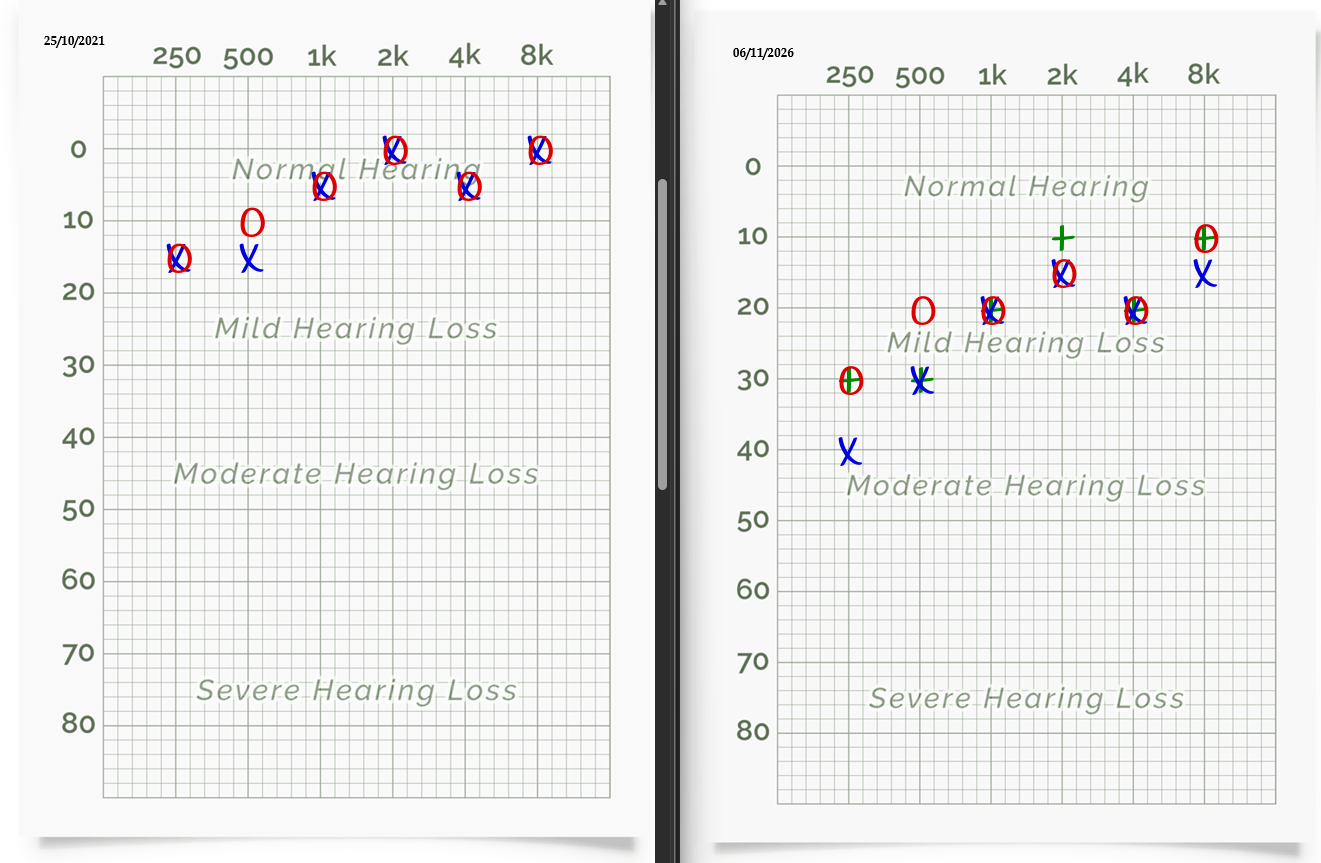